In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

df = pd.read_csv('market_features_weekly_std.csv')

df['Date'] = pd.to_datetime(df['Date'])

features = ['SP500_Return', 'VIX', 'Yield_Spread']

X = df[features].values

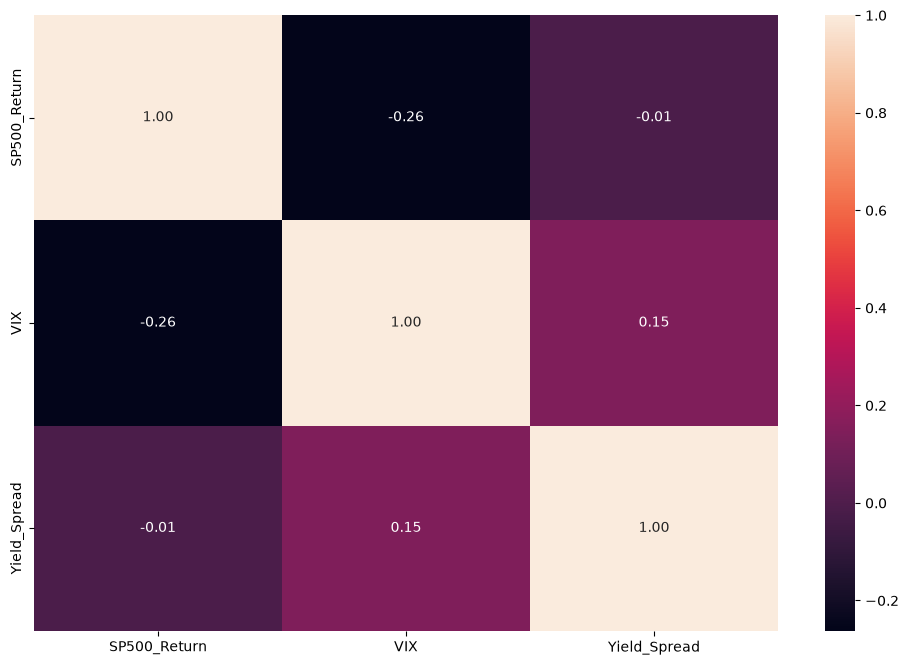

In [2]:
import seaborn as sns

cov_matrix = df[['SP500_Return', 'VIX', 'Yield_Spread']].cov()
plt.figure(figsize=(12, 8))
ax = sns.heatmap(cov_matrix, annot=True, fmt='.2f')
plt.show()
fig = ax.get_figure()
fig.savefig("out.svg", format="svg")

In [3]:
gmm = GaussianMixture(n_components=2, random_state=42)
gmm.fit(X)

# BIC per 1-5 componenti
bic_scores = []

for k in range(1, 6):
    gmm_k = GaussianMixture(n_components=k, random_state=42)
    gmm_k.fit(X)
    bic_scores.append(gmm_k.bic(X))
    print(f"Componenti: {k}, BIC: {bic_scores[-1]:.2f}")

print(f"Componenti con BIC minimo: {np.argmin(bic_scores) + 1}")

Componenti: 1, BIC: 13234.76
Componenti: 2, BIC: 12256.49
Componenti: 3, BIC: 12125.93
Componenti: 4, BIC: 11684.89
Componenti: 5, BIC: 11610.66
Componenti con BIC minimo: 5


In [4]:
# GMM con 5 componenti: pesi e varianze di ogni componente
gmm5 = GaussianMixture(n_components=5, random_state=42)
gmm5.fit(X)

print(f"BIC da 1 a 5: {np.round(bic_scores, 2)}")
print(f"Pesi: {np.round(gmm5.weights_, 3)}")
for i in range(5):
    print(f"Componente {i}: peso {gmm5.weights_[i]:.3f}, varianze {np.round(np.diag(gmm5.covariances_[i]), 3)}")

BIC da 1 a 5: [13234.76 12256.49 12125.93 11684.89 11610.66]
Pesi: [0.27  0.312 0.037 0.1   0.281]
Componente 0: peso 0.270, varianze [0.184 0.042 0.412]
Componente 1: peso 0.312, varianze [0.487 0.18  0.468]
Componente 2: peso 0.037, varianze [7.613 2.823 0.901]
Componente 3: peso 0.100, varianze [1.633 0.665 0.117]
Componente 4: peso 0.281, varianze [1.155 0.327 0.243]


In [5]:
df['regime'] = gmm.predict(X)
probs = gmm.predict_proba(X)
regime_stress = df.groupby('regime')['VIX'].mean().idxmax()
df['prob_stress'] = probs[:, regime_stress]

In [6]:
print(df.groupby('regime')[features].mean())

        SP500_Return       VIX  Yield_Spread
regime                                      
0           0.063097 -0.341798     -0.018427
1          -0.274861  1.488929      0.080271


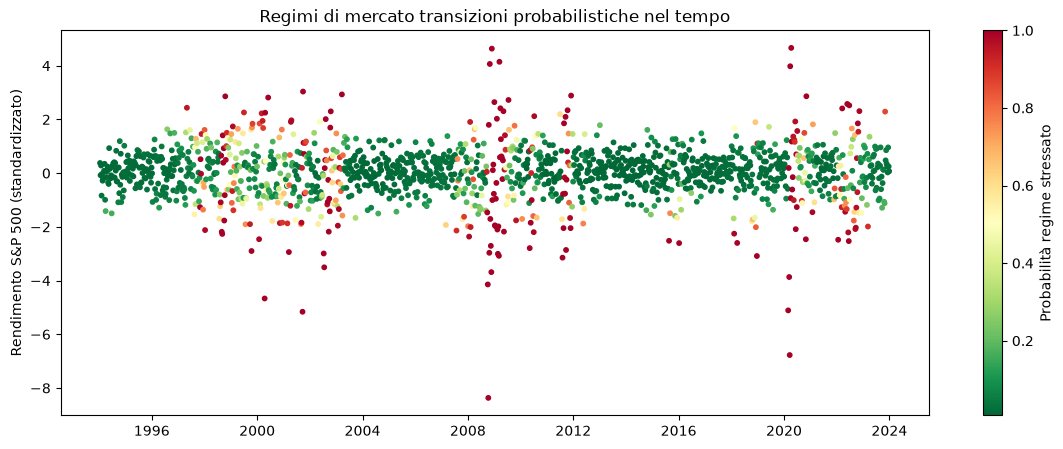

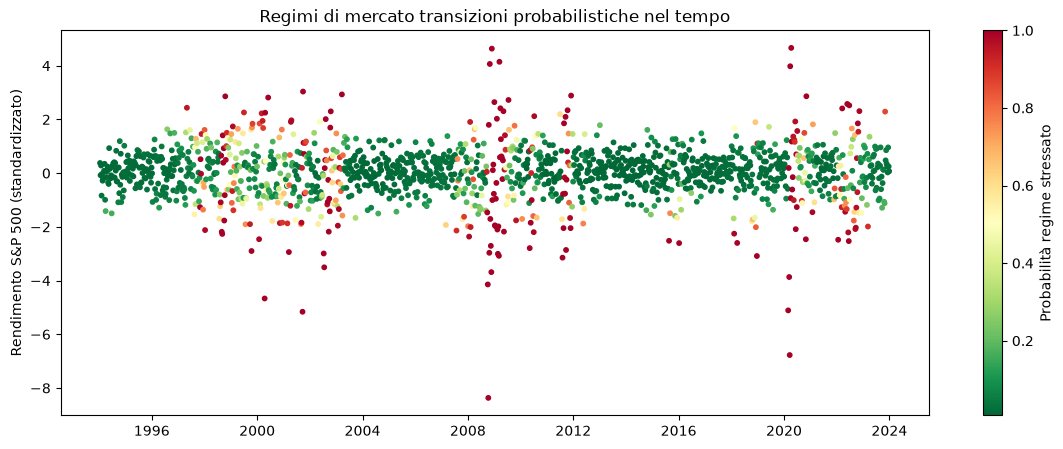

In [7]:
plt.figure(figsize=(14, 5))
plt.scatter(df['Date'], df['SP500_Return'], c=df['prob_stress'], cmap='RdYlGn_r', s=10)
plt.colorbar(label='Probabilità regime stressato')
plt.ylabel('Rendimento S&P 500 (standardizzato)')
plt.title('Regimi di mercato transizioni probabilistiche nel tempo')
plt.show()
plt.figure(figsize=(14, 5))
plt.scatter(df['Date'], df['SP500_Return'], c=df['prob_stress'], cmap='RdYlGn_r', s=10)
plt.colorbar(label='Probabilità regime stressato')
plt.ylabel('Rendimento S&P 500 (standardizzato)')
plt.title('Regimi di mercato transizioni probabilistiche nel tempo')
plt.show()